In [9]:
#Step 1: Import libraries and upload datasets

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import (
    VECM, select_coint_rank
)

uploaded = files.upload()

Saving price_data_cleaned_rajkot.xlsx to price_data_cleaned_rajkot (1).xlsx
Saving price_indore_market_cleaned_ffill_no_holidays_covid.csv to price_indore_market_cleaned_ffill_no_holidays_covid (1).csv


In [11]:
#Step 2: Load and prepare datarajkot = pd.read_excel("price_data_cleaned_rajkot.xlsx")

indore = pd.read_csv(
    "price_indore_market_cleaned_ffill_no_holidays_covid.csv"
)

rajkot["Date"] = pd.to_datetime(rajkot["Date"])
indore["date"] = pd.to_datetime(indore["date"])

gondal = rajkot[["Date", "p_modal"]].rename(
    columns={"Date": "date", "p_modal": "Gondal"}
)

indore_price = indore[["date", "p_modal"]].rename(
    columns={"p_modal": "Indore"}
)

gondal_monthly = (
    gondal.set_index("date")["Gondal"].resample("MS").mean()
)

indore_monthly = (
    indore_price.set_index("date")["Indore"].resample("MS").mean()
)

data = pd.concat(
    [gondal_monthly, indore_monthly], axis=1
).dropna()

data.index = pd.DatetimeIndex(data.index)
data = data.sort_index()
data = data.asfreq("MS")
data = data.dropna()

print(data.shape)
print(data.head())
print(data.isna().sum())

(178, 2)
                 Gondal       Indore
date                                
2011-01-01  2354.130435  2267.200000
2011-02-01  2327.391304  2278.304348
2011-03-01  2150.000000  2182.307692
2011-04-01  1990.238095  2210.227273
2011-05-01  1918.541667  2188.520000
Gondal    0
Indore    0
dtype: int64


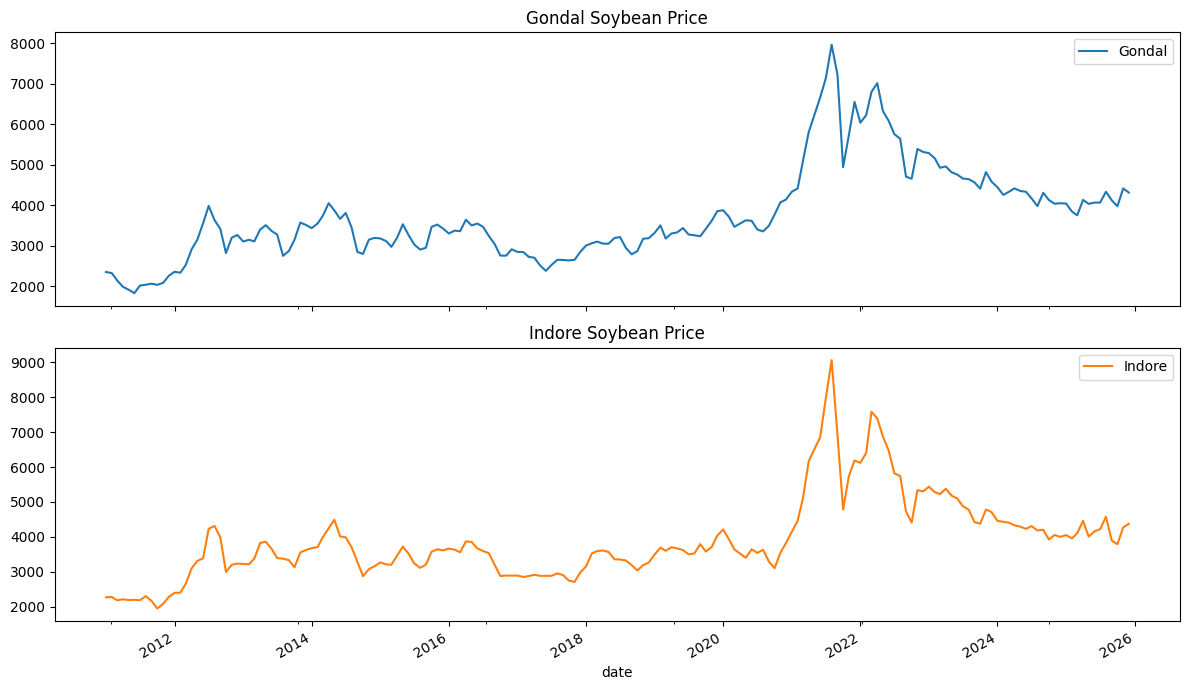

In [12]:
#Step 3: Plot both price series

data.plot(
    subplots=True,
    figsize=(12, 7),
    title=["Gondal Soybean Price", "Indore Soybean Price"]
)
plt.tight_layout()
plt.show()

In [13]:
#Step 4: ADF stationarity tests

def adf_test(series, name):
    result = adfuller(series.dropna(), autolag="AIC")
    print(f"\n{name}")
    print("ADF Statistic:", result[0])
    print("p-value:", result[1])
    print("Stationary at 5%:", result[1] < 0.05)

for col in data.columns:
    adf_test(data[col], f"{col} Price Level")
    adf_test(data[col].diff(), f"{col} First Difference")


Gondal Price Level
ADF Statistic: -2.1885544991406456
p-value: 0.21042570786682713
Stationary at 5%: False

Gondal First Difference
ADF Statistic: -11.524098063015552
p-value: 3.974708237777999e-21
Stationary at 5%: True

Indore Price Level
ADF Statistic: -2.0105589951070226
p-value: 0.2819626251633186
Stationary at 5%: False

Indore First Difference
ADF Statistic: -7.632262052162005
p-value: 1.994409396657866e-11
Stationary at 5%: True


/tmp/ipykernel_2143/1643528685.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag="AIC")
/tmp/ipykernel_2143/1643528685.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag="AIC")
/tmp/ipykernel_2143/1643528685.py:2: FutureWarning: adfuller currently returns a plain tuple whose length de

In [14]:
#Step 5: VAR lag-order selection

lag_selection = VAR(data).select_order(maxlags=12)
print(lag_selection.summary())

p = lag_selection.selected_orders["bic"]
print("BIC-selected VAR lag order:", p)

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0        24.90       24.94   6.506e+10       24.91
1        22.25       22.36   4.613e+09       22.30
2        22.09       22.27   3.907e+09       22.16
3        21.96      22.23*   3.461e+09       22.07
4        21.93       22.27   3.347e+09      22.07*
5       21.93*       22.34  3.340e+09*       22.10
6        21.94       22.42   3.367e+09       22.13
7        21.97       22.54   3.495e+09       22.20
8        21.97       22.61   3.480e+09       22.23
9        22.00       22.71   3.578e+09       22.29
10       21.97       22.75   3.475e+09       22.29
11       21.99       22.85   3.557e+09       22.34
12       21.95       22.89   3.433e+09       22.33
--------------------------------------------------
BIC-selected VAR lag order: 3


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


In [15]:
#Step 6: Johansen cointegration test

k_ar_diff = max(0, p - 1)

rank_test = select_coint_rank(
    data,
    det_order=0,
    k_ar_diff=k_ar_diff,
    method="trace",
    signif=0.05
)

print(rank_test.summary())
print("Cointegration rank:", rank_test.rank)

Johansen cointegration test using trace test statistic with 5% significance level
r_0 r_1 test statistic critical value
-------------------------------------
  0   2          44.55          15.49
  1   2          3.109          3.841
-------------------------------------
Cointegration rank: 1


In [16]:
#Step 7: Fit VECM

vecm_final = VECM(
    data,
    k_ar_diff=3,
    coint_rank=1,
    deterministic="ci"
).fit()

print(vecm_final.summary())

Det. terms outside the coint. relation & lagged endog. parameters for equation Gondal
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
L1.Gondal     -0.4939      0.156     -3.170      0.002      -0.799      -0.189
L1.Indore      0.7631      0.130      5.852      0.000       0.508       1.019
L2.Gondal     -0.3602      0.144     -2.501      0.012      -0.643      -0.078
L2.Indore     -0.0374      0.123     -0.304      0.761      -0.279       0.204
L3.Gondal     -0.2572      0.129     -1.992      0.046      -0.510      -0.004
L3.Indore      0.3691      0.116      3.193      0.001       0.143       0.596
Det. terms outside the coint. relation & lagged endog. parameters for equation Indore
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
L1.Gondal     -0.5537      0.187     -

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


In [17]:
#Step 8: Residual autocorrelation test

whiteness_test = vecm_final.test_whiteness(
    nlags=12,
    adjusted=True
)

print(whiteness_test.summary())

Adjusted Portmanteau-test for residual autocorrelation. H_0: residual autocorrelation up to lag 12 is zero. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
         43.18          48.60   0.135 34
----------------------------------------


In [18]:
#Step 9: Residual normality test

normality_test = vecm_final.test_normality()
print(normality_test.summary())

normality (skew and kurtosis) test. H_0: data generated by normally-distributed process. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
         268.4          9.488   0.000  4
----------------------------------------


In [19]:
#Step 10: Calculate the error-correction coefficients

alpha = vecm_final.alpha[:, 0]
beta = vecm_final.beta[:, 0]

print("Alpha coefficients:", alpha)
print("Beta coefficients:", beta)
print("beta' alpha:", beta @ alpha)

Alpha coefficients: [0.44394564 0.95331317]
Beta coefficients: [ 1.         -1.03565647]
beta' alpha: -0.543359310706363


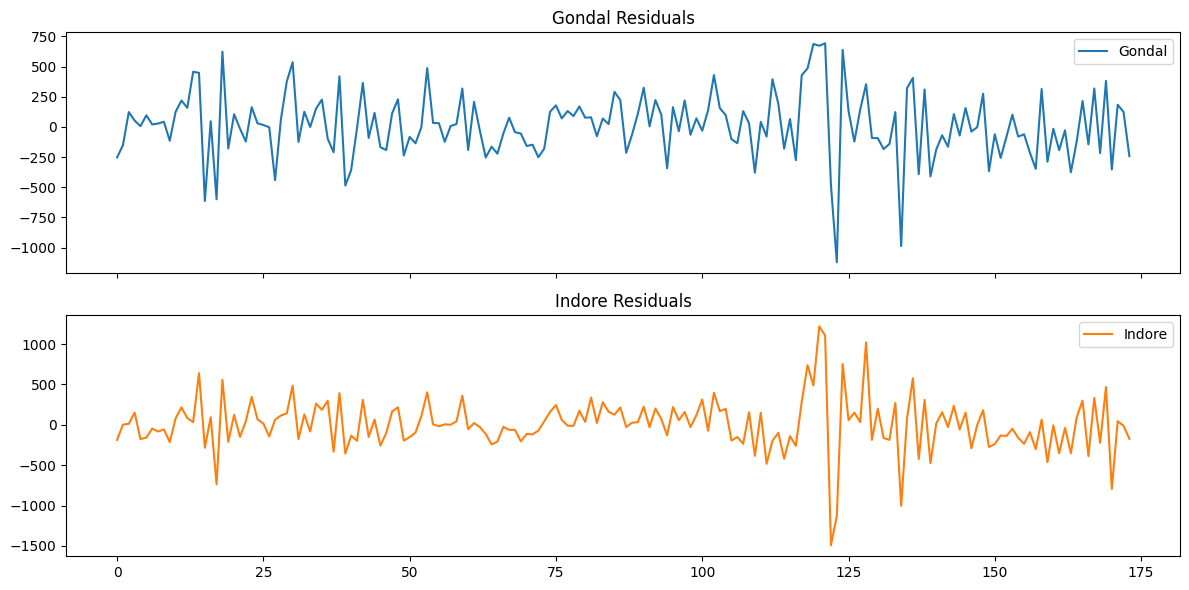

In [20]:
#Step 11: Plot VECM residuals

residuals = pd.DataFrame(
    vecm_final.resid,
    columns=data.columns
)

residuals.plot(
    subplots=True,
    figsize=(12, 6),
    title=["Gondal Residuals", "Indore Residuals"]
)

plt.tight_layout()
plt.show()

In [21]:
#Step 12: Fit VAR on first-differenced prices

diff_data = data.diff().dropna()

diff_lags = VAR(diff_data).select_order(maxlags=12)
print(diff_lags.summary())

diff_p = diff_lags.selected_orders["bic"]

var_diff = VAR(diff_data).fit(maxlags=max(1, diff_p))

print(var_diff.summary())

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0        22.52       22.55   6.002e+09       22.53
1        22.42       22.53   5.434e+09       22.46
2        22.18      22.37*   4.306e+09       22.26
3        22.15       22.41   4.171e+09      22.26*
4        22.17       22.51   4.240e+09       22.31
5        22.15       22.56   4.151e+09       22.31
6        22.11       22.60   4.006e+09       22.31
7        22.09       22.65   3.911e+09       22.32
8        22.11       22.75   4.004e+09       22.37
9       22.05*       22.77  3.783e+09*       22.34
10       22.06       22.85   3.833e+09       22.39
11       22.06       22.93   3.838e+09       22.42
12       22.11       23.05   4.009e+09       22.49
--------------------------------------------------
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sat, 24, Oct

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


In [22]:
#Step 13: Check VAR residual autocorrelation

var_whiteness = var_diff.test_whiteness(
    nlags=12,
    adjusted=True
)

print(var_whiteness.summary())

Adjusted Portmanteau-test for residual autocorrelation. H_0: residual autocorrelation up to lag 12 is zero. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
         70.64          55.76   0.002 40
----------------------------------------


In [23]:
#Step 14: Check VAR residual normality

print(var_diff.test_normality().summary())

normality (skew and kurtosis) test. H_0: data generated by normally-distributed process. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
         527.4          9.488   0.000  4
----------------------------------------


In [24]:
#Step 15: Check VAR stability

print("VAR stable:", var_diff.is_stable())
print("Characteristic roots:", var_diff.roots)

VAR stable: True
Characteristic roots: [ 0.74659405+1.58994359j  0.74659405-1.58994359j -0.53240376+1.52055413j
 -0.53240376-1.52055413j]


In [25]:
#Step 16: Forecast using the differenced VAR

from sklearn.metrics import mean_absolute_error, mean_squared_error

n_test = 12

train = data.iloc[:-n_test]
test = data.iloc[-n_test:]

train_diff = train.diff().dropna()

lag_result = VAR(train_diff).select_order(maxlags=12)
p_test = lag_result.selected_orders["bic"]

var_train = VAR(train_diff).fit(maxlags=max(1, p_test))

forecast_diff = var_train.forecast(
    train_diff.values[-var_train.k_ar:],
    steps=n_test
)

forecast_diff = pd.DataFrame(
    forecast_diff,
    index=test.index,
    columns=data.columns
)

# Reconstruct price levels from the final training observations
forecast_levels = forecast_diff.cumsum()
forecast_levels = forecast_levels.add(train.iloc[-1], axis="columns")

for col in data.columns:
    mae = mean_absolute_error(test[col], forecast_levels[col])
    rmse = np.sqrt(mean_squared_error(test[col], forecast_levels[col]))

    print(f"\n{col}")
    print("MAE:", mae)
    print("RMSE:", rmse)


Gondal
MAE: 120.18713920077387
RMSE: 158.14700194557824

Indore
MAE: 234.89009169227617
RMSE: 281.700160459768


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


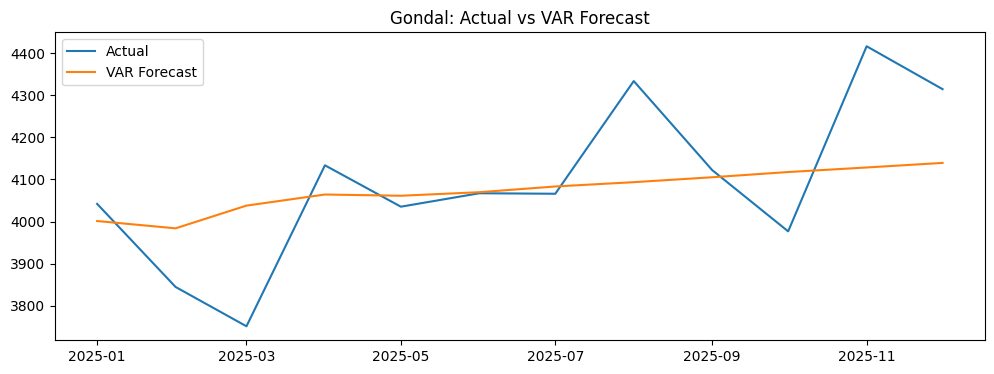

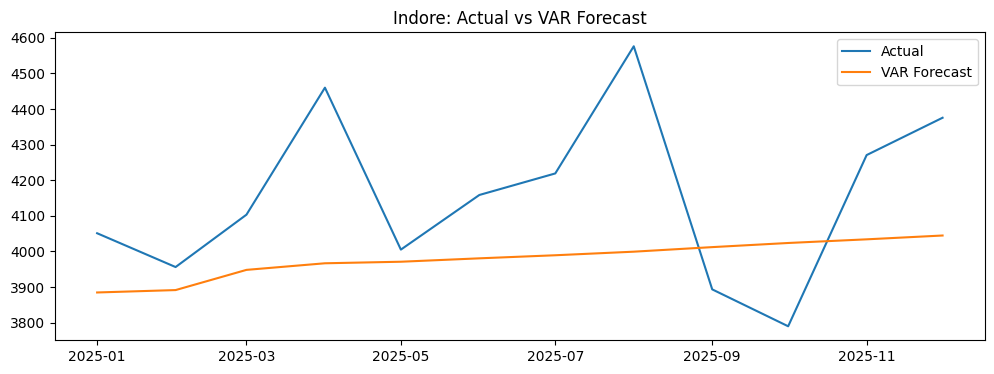

In [26]:
#Step 17: Plot actual versus forecast prices

for col in data.columns:
    plt.figure(figsize=(12, 4))
    plt.plot(test.index, test[col], label="Actual")
    plt.plot(test.index, forecast_levels[col], label="VAR Forecast")
    plt.title(f"{col}: Actual vs VAR Forecast")
    plt.legend()
    plt.show()

In [27]:
#Step 18: Save your model results

results = pd.DataFrame({
    "Actual_Gondal": test["Gondal"],
    "Forecast_Gondal": forecast_levels["Gondal"],
    "Actual_Indore": test["Indore"],
    "Forecast_Indore": forecast_levels["Indore"]
})

results.to_csv("VAR_forecast_results.csv", index=True)